# Exercise: EDM or rap?

Can a model predict an **EDM** song from a **rap** song?

Today we will compare at how logistic regression and random forest models approach this question.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   ma

## The data

Each row is one song from a Spotify playlist. We keep the EDM songs and the rap songs.

| column | meaning |
|---|---|
| `track_name` | name of the song |
| `track_artist` | who made the song |
| `genre` | `rap` or `edm` |
| `danceability` | how good the song is for dancing, from 0 to 1 |
| `tempo` | speed of the beat, in beats per minute (BPM) |

Source: [TidyTuesday, 2020-01-21](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-01-21) (from the Spotify API, via the `spotifyr` package).

Some songs are on more than one playlist. `distinct()` keeps each song one time. We put `rap` first in the factor, so `edm` is the event the model predicts.

In [9]:
songs <- read.csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-01-21/spotify_songs.csv')

songs <- songs |>
    filter(playlist_genre %in% c('edm', 'rap')) |>
    distinct(track_id, .keep_all = TRUE) |>
    mutate(genre = factor(playlist_genre, levels = c('rap', 'edm'))) |>
    select(track_name, track_artist, genre, danceability, tempo)

songs |> count(genre)

  genre n   
1 rap   5486
2 edm   5437

## 1. Look at the data

Plot `tempo` (y-axis) against `danceability` (x-axis). Color the points by `genre`. There are many points, so use `alpha = 0.2` and `size = 0.5`.

<details>
<summary>Hint</summary>

```R
ggplot(songs, aes(x = danceability, y = tempo, color = genre)) +
    geom_point(alpha = 0.2, size = 0.5)
```

</details>

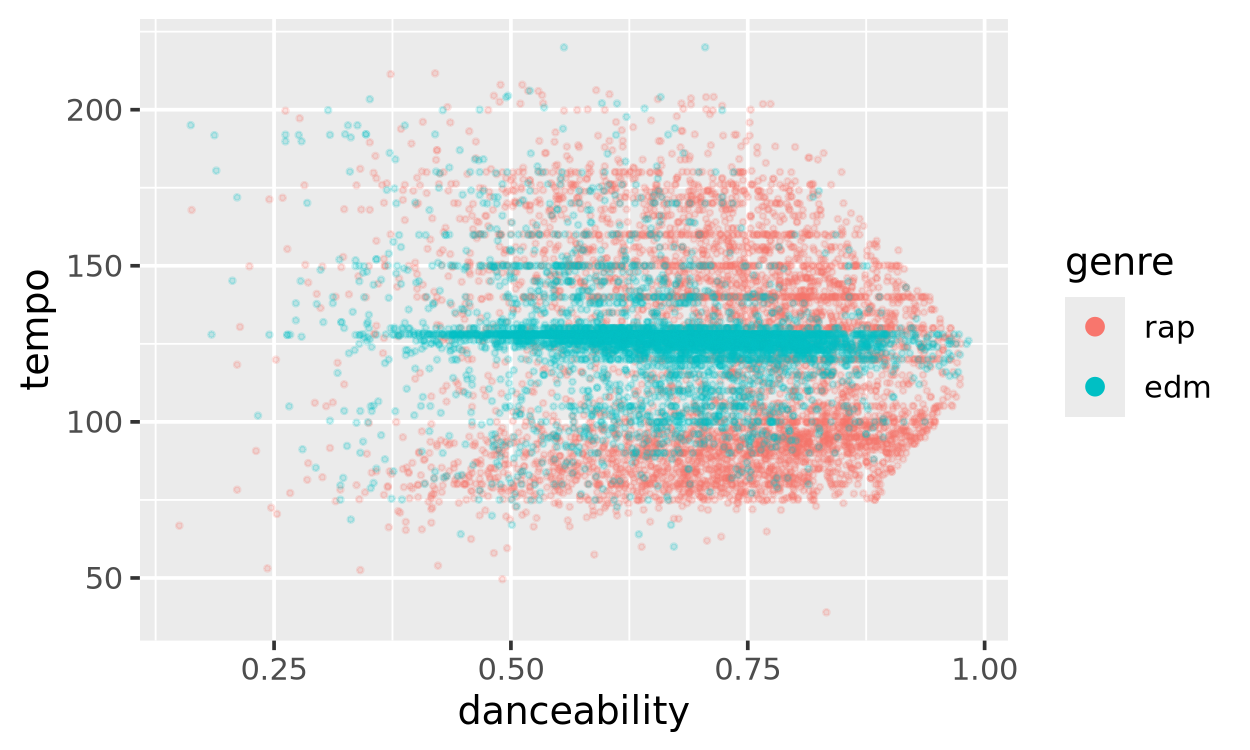

In [13]:
ggplot(songs, aes(x = danceability, y = tempo, color = genre)) +
    geom_point(alpha = .2, size = .5) +
    guides(color = guide_legend(override.aes = list(size = 2, alpha = 1)))

Where are most of the EDM songs? Where are most of the rap songs? Can you draw **one straight line** that puts the EDM songs on one side and the rap songs on the other? Can you make the legend points larger (you can ask an LLM how to do this)?

## 2. From a probability to a prediction

Fit `genre ~ danceability + tempo` with `logistic_reg()`. Save it as `fit_logit`.

Then predict on `songs` with `type = 'prob'` and bind the predictions to `songs`. Save it as `preds`.

Make a new column `guess` with the 0.5 rule: `'edm'` if `.pred_edm` is more than 0.5, `'rap'` if not. Then find the accuracy: the mean of `guess == genre`.

<details>
<summary>Hint</summary>

```R
fit_logit <- logistic_reg() |> fit(genre ~ danceability + tempo, data = songs)

preds <- fit_logit |>
    predict(new_data = songs, type = 'prob') |>
    bind_cols(songs) |>
    mutate(guess = if_else(.pred_edm > 0.5, 'edm', 'rap'))

preds |> summarize(accuracy = mean(guess == genre))
```

</details>

In [4]:
fit_logit <- logistic_reg() |> fit(genre ~ danceability + tempo, data = songs)

parsnip model object


Call:  stats::glm(formula = genre ~ danceability + tempo, family = stats::binomial, 
    data = data)

Coefficients:
 (Intercept)  danceability         tempo  
    1.563892     -3.327557      0.005808  

Degrees of Freedom: 10922 Total (i.e. Null);  10920 Residual
Null Deviance:	    15140 
Residual Deviance: 14550 	AIC: 14560

In [17]:
preds <- fit_logit |>
    predict(new_data = songs, type = 'prob') |>
    bind_cols(songs) |>
    mutate(guess = if_else(.pred_edm > 0.5, 'edm', 'rap'))

In [18]:
preds |> summarize(accuracy = mean(guess == genre))

  accuracy 
1 0.6025817

**Check:** the accuracy should be about 0.60.

About half of the songs are EDM. So a model that just predicts all songs are EDM is right about 0.50 of the time. Is 0.60 good?

Bonus check: predict with `type = 'class'` and compare `.pred_class` with your `guess` column. They should be the same.

## 3. The logistic regression boundary

Make a grid:

```R
grid <- crossing(danceability = seq(0.2, 1, by = 0.01), tempo = seq(60, 210, by = 1))
```

Copy the `plot_boundary()` function from the lecture into the cell below. Change it for this data:

- `x = danceability`, `y = tempo`
- `.pred_edm` instead of `.pred_yes`

Then run `plot_boundary(fit_logit, grid)`.

<details>
<summary>Hint</summary>

```R
grid <- crossing(danceability = seq(0.2, 1, by = 0.01), tempo = seq(60, 210, by = 1))

plot_boundary <- function(fit, grid) {
    preds <- fit |>
        predict(new_data = grid, type = 'prob') |>
        bind_cols(grid)

    ggplot(preds, aes(x = danceability, y = tempo)) +
        geom_tile(aes(fill = .pred_edm)) +
        geom_contour(aes(z = .pred_edm), breaks = 0.5, color = 'black') +
        scale_fill_gradient2(low = 'steelblue', mid = 'white', high = 'darkorange',
                             midpoint = 0.5, limits = c(0, 1))
}

plot_boundary(fit_logit, grid)
```

</details>

In [19]:
grid <- crossing(danceability = seq(0.2, 1, by = 0.01), tempo = seq(60, 210, by = 1))

In [25]:
plot_boundary <- function(fit, grid) {
    preds <- fit |>
        predict(new_data = grid, type = 'prob') |>
        bind_cols(grid)

ggplot(preds, aes(x = danceability, y = tempo)) +
        geom_tile(aes(fill = .pred_edm)) +
        geom_contour(aes(z = .pred_edm), breaks = 0.5, color = 'black') +
        scale_fill_gradient2(low = 'steelblue', mid = 'white', high = 'darkorange',
                             midpoint = 0.5, limits = c(0, 1))
}

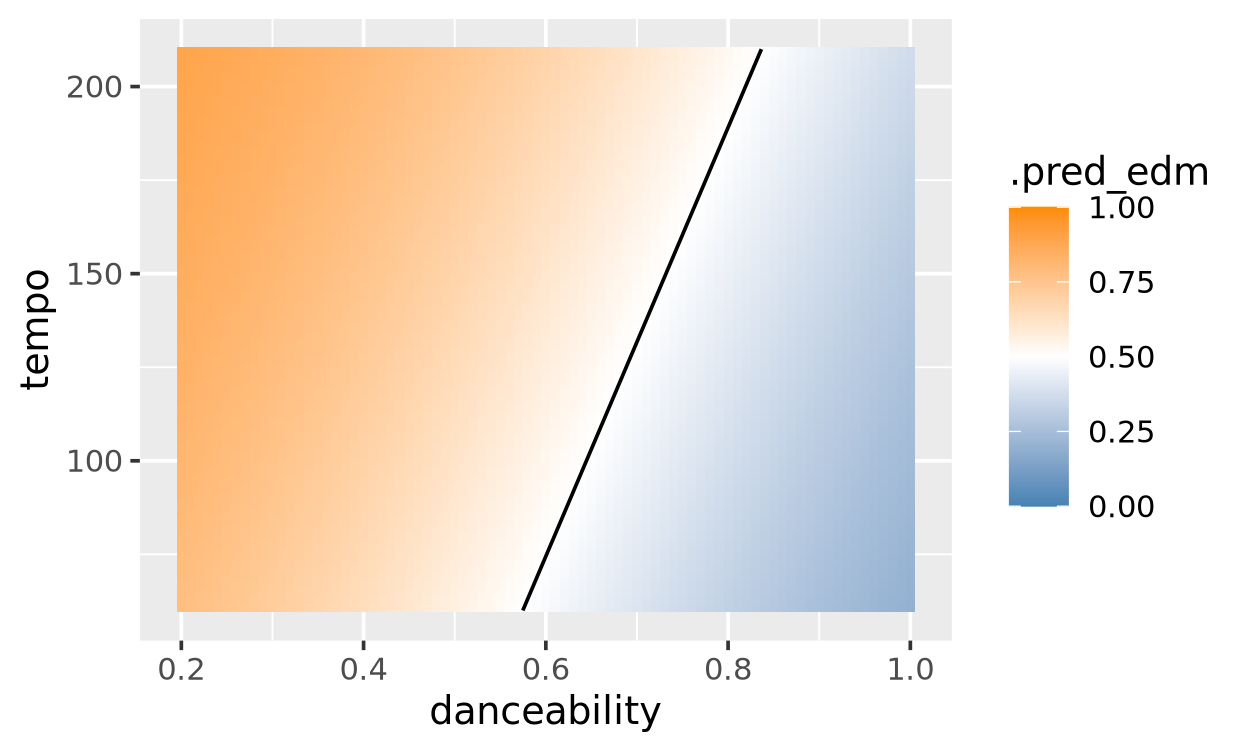

In [26]:
plot_boundary(fit_logit, grid)

**Check:** you should see one straight black line. Low danceability is orange (guess EDM). High danceability is blue (guess rap).

Compare with your plot in step 1. What does this line miss?

## 4. AI step: a random forest

Open a terminal and run `opencode`.

**Copy this prompt into opencode:**

```text
I am working in exercises/13-spotify-exercise.ipynb, with R and tidymodels.
The data frame songs has a factor column genre (rap or edm) and two number
columns, danceability and tempo.

In the empty code cell in step 4, fit a random forest of
genre ~ danceability + tempo with rand_forest(trees = 200),
set_mode('classification'), and set_engine('ranger'). Call set.seed(512)
first. Save it as fit_rf. Run the cell. Use tidymodels only. Do not change
any other cells.
```

**Your assistant puts its code in the cell below and runs it.** Read the code. Does it use `rand_forest()`? Does it call `set.seed()` before the fit?

In [27]:
set.seed(512)

fit_rf <- rand_forest(trees = 200) |>
    set_mode('classification') |>
    set_engine('ranger') |>
    fit(genre ~ danceability + tempo, data = songs)

fit_rf

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, num.trees = 200,      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  200 
Sample size:                      10923 
Number of independent variables:  2 
Mtry:                             1 
Target node size:                 10 
Variable importance mode:         none 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.1305407 

## 5. The random forest boundary

Run `plot_boundary(fit_rf, grid)`.

Then find the accuracy of `fit_rf` on `songs`. Use `type = 'class'` this time.

<details>
<summary>Hint</summary>

```R
plot_boundary(fit_rf, grid)

fit_rf |>
    predict(new_data = songs, type = 'class') |>
    bind_cols(songs) |>
    summarize(accuracy = mean(.pred_class == genre))
```

</details>

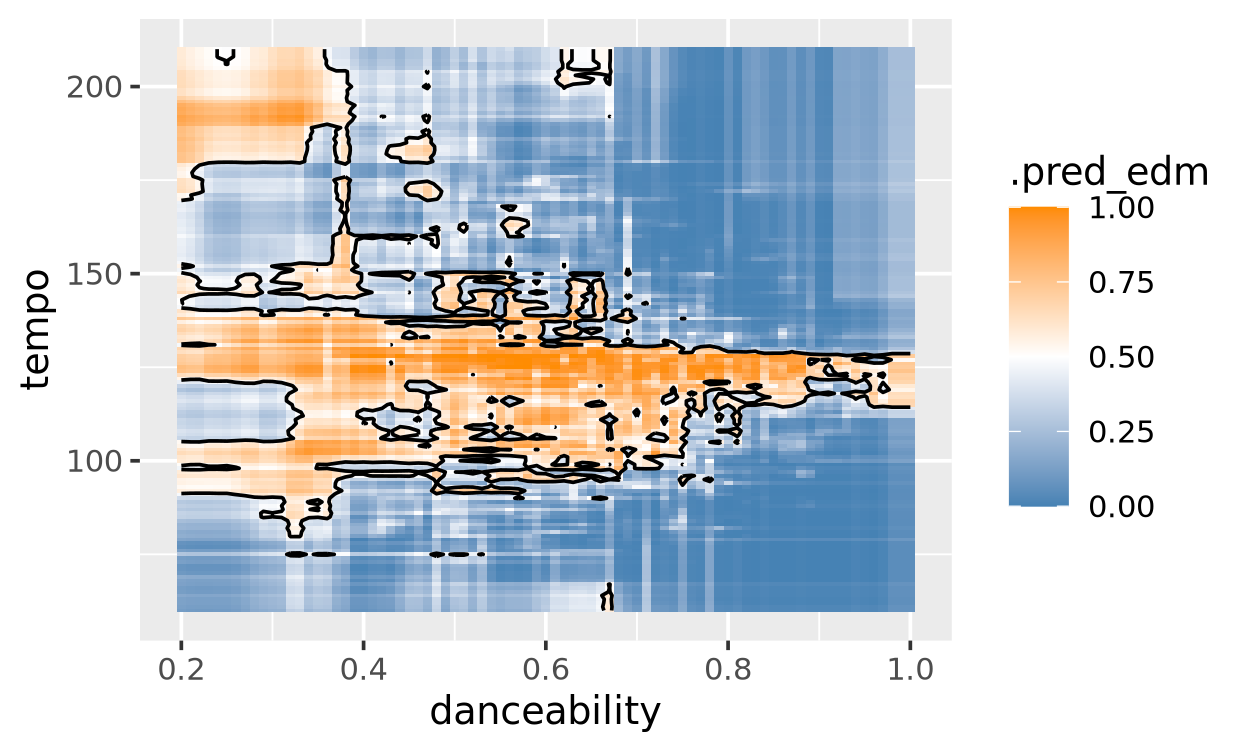

In [28]:
plot_boundary(fit_rf, grid)

In [29]:
fit_rf |> predict(new_data = songs, type = 'class') |>
        bind_cols(songs) |>
        summarize(accuracy = mean(.pred_class == genre))

  accuracy 
1 0.9371052

**Check:** you should see an orange **stripe** across the plot, near 125 BPM. The accuracy should be about 0.94.

- Look at the step 1 plot again. Why is there a stripe? (Hint: many EDM songs have a beat of about 125 to 130 BPM.)
- Why can't logistic regression draw a stripe?
- The lecture said to be careful with accuracy on the same songs we used to fit the model. Look for small islands in your plot. Do you think 0.94 is too high?